# Supply-line underweighting: a GPT beer-game experiment
Based on **`Project/Thoughts reflection.docx`** (not `Thoughts reflection#2.docx`).

This notebook runs a four-role beer game through the OpenAI API and estimates supply-line weight **β from ordering behavior**. It implements the document's training × decision-deadline design. GPT agents are experimental proxies, **not undergraduate participants**; their results cannot establish the document's human hypotheses.

**Quick start**
1. Run the installation cell once if needed, then restart the Python kernel.
2. Run all cells with `MODE = "offline"` to check the entire pipeline without an API key or charges. These outputs are labeled synthetic.
3. Set `MODE = "api"`, choose an accessible `MODEL`, and run all cells again. Supply `OPENAI_API_KEY` through your environment or the hidden key prompt. Never paste a key into a code cell.
4. Begin with the default **384-request pilot**. For the document's 240-participant layout, set `GROUPS_PER_CELL = 15` (60 groups × 4 roles). Choose the number of weeks before collecting data; 36 weeks requires **8,640 requests**.
5. Results, full prompts, API metadata, fit diagnostics, and figures are saved in `results/<mode>_<configuration hash>/`. Interrupted runs reuse completed request files. Change `REPLICATE_ID` to collect a new sample with otherwise identical settings.

The API follows the official [Structured Outputs guide](https://developers.openai.com/api/docs/guides/structured-outputs). Model access depends on your API account. This notebook does not assume a ChatGPT subscription provides API access.

The configurable default is [GPT-4.1 mini](https://developers.openai.com/api/docs/models/gpt-4.1-mini). For a study, use an available dated model snapshot and keep it fixed across conditions.

**API fix (protocol 1.1):** the failed run returned `credit_balance_exhausted`. Add prepaid API credits at https://platform.openai.com/settings/organization/billing/overview. This notebook now checks access before the experiment and stops clearly on API errors. The current settings preserve your 4 groups per condition and 36 weeks; the replicate is `api-pilot-02` to avoid the failed run.


In [6]:
# Uncomment once to install into this notebook's kernel, then restart the kernel.
# %pip install "openai>=2,<3" "pydantic>=2.8,<3" numpy pandas scipy matplotlib ipykernel


## 1. Design and interpretation

| Instructions | Deadline | Agents per group | Full design |
|---|---:|---:|---:|
| Standard | 60 seconds | 4 | 15 groups / 60 agents |
| Trained | 60 seconds | 4 | 15 groups / 60 agents |
| Standard | 120 seconds | 4 | 15 groups / 60 agents |
| Trained | 120 seconds | 4 | 15 groups / 60 agents |

- **H1:** β(trained) − β(standard) > 0, separately at each deadline; also report an equally weighted average of those two contrasts.
- **H2:** β(trained, 60 s) − β(trained, 120 s) < 0.
- Report the training × deadline interaction as an exploratory contrast.

**Choices needed because the reflection leaves them unspecified:** treatment is assigned to whole groups to avoid within-chain training spillover; the roles are retailer, wholesaler, distributor, and factory. This estimates a *whole-chain training effect*, rather than an isolated individual's direct effect. Group execution order is randomized. All groups face the same customer-demand path, unknown to agents in advance. Agents receive only local state and their own complete past round records. No demographic personas are invented.

**Time manipulation:** both the prompt and an actual wall-clock request deadline use 60/120 seconds. The output-token allowance, model, and all other API settings stay equal. Network/queue latency is part of this interval; it is not a measurement of cognition. No sleep is added to imitate deliberation. If every response finishes well below 60 seconds, the deadline probably did not bind. A model can also react to the deadline wording without using more computation. These are limitations on interpreting H2, not evidence that knowledge caused the result.

A timed-out or unusable response uses the previous order (4 initially), and is explicitly logged. Connection errors get up to three attempts within the original deadline. Other API exceptions—including depleted credits and rate limits—stop the experiment after the current four requests finish saving. They are never silently used as experimental decisions. Any group affected by such a fallback is excluded from the **complete-group primary β contrasts** because failures propagate through the chain. All groups remain in descriptive costs/latency reporting. Differential failures can bias complete-group comparisons; inspect the failure table before interpretation. SDK retries are disabled so the deadline is not repeatedly restarted.


In [7]:
import asyncio
import getpass
import hashlib
import json
import os
import platform
import time
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from pydantic import BaseModel, ConfigDict, Field
from openai import AsyncOpenAI
from IPython.display import display

MODE = "api"                    # "offline" (synthetic) or "api" (paid calls)
MODEL = os.environ.get("OPENAI_MODEL", "gpt-4.1-mini")
GROUPS_PER_CELL = 4                  # Pilot only; use 15 for 240 agents
WEEKS = 36                          # Set 36 for the longer study
REPLICATE_ID = "api-pilot-02"            # Change to collect fresh responses
SEED = 20260926                      # Schedule/offline RNG only; does not seed GPT
MAX_OUTPUT_TOKENS = 512              # Identical in all four conditions
BOOTSTRAP_REPS = 2000
MIN_GROUPS_FOR_INTERVAL = 5          # Exploratory intervals; 15/cell is still small
ROLES = ("retailer", "wholesaler", "distributor", "factory")
PROTOCOL_VERSION = "1.1"
RESUME_RUN_DIR = "api_023f89662165ca64"  # Resume saved successes; None starts a fresh run

# Locate the output directory from either the workspace or the notebook folder.
BASE = Path.cwd()
if (BASE / "Project" / "beer_game_experiment").is_dir():
    BASE = BASE / "Project" / "beer_game_experiment"
elif (BASE / "beer_game_experiment").is_dir():
    BASE = BASE / "beer_game_experiment"

assert MODE in {"offline", "api"}
assert GROUPS_PER_CELL >= 1 and WEEKS >= 16
DEMAND = [4 if w < 5 else 8 for w in range(1, WEEKS + 1)]
print(f"{MODE.upper()}: {4 * GROUPS_PER_CELL} groups; "
      f"{16 * GROUPS_PER_CELL} agents; "
      f"up to {16 * GROUPS_PER_CELL * WEEKS:,} requests (zero in offline mode).")


API: 16 groups; 64 agents; up to 2,304 requests (zero in offline mode).


## 2. Beer-game mechanics

The implementation is an explicit adaptation, not a claim to reproduce every historical board-game rule. [Sterman's MIT description](https://web.mit.edu/jsterman/www/SDG/beergame.html) provides the four roles, initial stock of 12, initial flow of 4, holding/backlog costs of 0.5/1 per unit-week, and the demand step from 4 to 8 in week 5.

Each week: receive deliveries → receive downstream orders → ship against current orders plus backlog → observe local state → decide orders simultaneously. Customer orders arrive immediately at the retailer. Orders between roles take **one week**; shipments take **two weeks** from dispatch. Factory production takes **three weeks** from placement. There is no capacity limit, cancellation, or inventory disposal. Initial queues are filled with 4 to start in equilibrium (stock stays at 12 if demand and orders remain 4).

**Supply line** means *all units already ordered but not yet received*, including goods not yet shipped, not just the shipping queue. At the decision point, today's new order is excluded. Each period obeys `next outstanding = previous outstanding − receipts + new order`. Costs use inventory/backlog after shipping. All four decisions use the same pre-order snapshot, so no role sees another role's current decision.


In [8]:
@dataclass(frozen=True)
class Condition:
    trained: bool
    deadline_s: int

CONDITIONS = [Condition(t, d) for d in (60, 120) for t in (False, True)]

class BeerGame:
    def __init__(self):
        self.inventory = np.full(4, 12, dtype=int)
        self.backlog = np.zeros(4, dtype=int)
        self.delivery = [[4, 4] for _ in range(3)] + [[4, 4, 4]]
        self.incoming = np.full(3, 4, dtype=int)
        self.outstanding = np.full(4, 12, dtype=int)
        self.week = 0
        self.awaiting_orders = False

    def observe(self, customer_demand):
        assert not self.awaiting_orders, "Commit orders before advancing."
        self.week += 1
        receipts = np.array([queue.pop(0) for queue in self.delivery])
        self.inventory += receipts
        self.outstanding -= receipts
        demands = np.r_[customer_demand, self.incoming].astype(int)
        owed = self.backlog + demands
        shipped = np.minimum(self.inventory, owed)
        self.inventory -= shipped
        self.backlog = owed - shipped
        # Shipments made this week arrive two weeks later downstream.
        for downstream in range(3):
            self.delivery[downstream].append(int(shipped[downstream + 1]))
        self.awaiting_orders = True
        assert (self.inventory >= 0).all() and (self.outstanding >= 0).all()
        return [dict(week=self.week, role=ROLES[i], demand=int(demands[i]),
                     received=int(receipts[i]), shipped=int(shipped[i]),
                     inventory=int(self.inventory[i]), backlog=int(self.backlog[i]),
                     net_inventory=int(self.inventory[i] - self.backlog[i]),
                     supply_line=int(self.outstanding[i]),
                     cost=float(0.5 * self.inventory[i] + self.backlog[i]))
                for i in range(4)]

    def commit(self, orders):
        assert self.awaiting_orders
        assert len(orders) == 4 and all(isinstance(x, int) and x >= 0 for x in orders)
        self.outstanding += np.array(orders, dtype=int)
        self.incoming = np.array(orders[:3], dtype=int)
        self.delivery[3].append(orders[3])
        self.awaiting_orders = False
        # Outstanding goods = shipping queue + supplier backlog + order in transit.
        for i in range(3):
            assert self.outstanding[i] == sum(self.delivery[i]) + self.backlog[i+1] + orders[i]
        assert self.outstanding[3] == sum(self.delivery[3])


## 3. Instructions and API decisions

Only the training paragraph and deadline text vary by condition. The training explains delayed deliveries and pending orders without naming the hypotheses, prescribing β, or telling GPT to imitate errors. The standard group is still given field definitions, so the manipulation is conceptual instruction rather than access to hidden data. The offline policy is identical across treatments and is only a software check.

Each role is a separate decision history. Requests are stateless (`store=False`); its local history is explicitly included. Responses contain only an integer order. No GPT self-reported β or explanation is used as the outcome.


In [9]:
STANDARD = """You manage one role in a four-stage beer supply chain.
Minimize total team holding and backlog costs over repeated weeks.
Holding one unit costs 0.5 per week; backlogging one unit costs 1 per week.
You can only observe your own role. Do not communicate with other roles.
Orders travel upstream in one week; shipments travel downstream in two weeks.
The factory's production takes three weeks. Suppliers may be backlogged.
There is no production capacity limit. Orders cannot be canceled.
Inventory is available stock; backlog is unfilled demand from your customer.
Net inventory is inventory minus backlog. Supply line is the total quantity
previously ordered but not yet received. Decisions occur after receiving and
shipping this week's goods, before placing this week's order.
Demand may change. Future demand and the final week are not disclosed.
Choose a nonnegative integer order using the provided local observations.
Return only the structured order response."""
TRAINING = """Additional supply-chain training:
An outstanding order remains in the system while it is being processed or
shipped, even when it has not reached your shelves. A delivery delay does not
mean that the order disappeared. Review available stock, unfilled customer
demand, and pending replenishment together before ordering. Repeatedly
replacing the same shortfall during a delivery delay can create excess stock
when earlier orders arrive. Account for delivery delays when planning."""

class OrderDecision(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order: int = Field(ge=0, le=1000000)

# The very high validation ceiling is a numerical guard, not an order target.
# Responses outside this range are invalid, logged, and trigger the failure rule.
def make_messages(condition, state, history):
    instructions = STANDARD + ("\n" + TRAINING if condition.trained else "")
    instructions += (f"\nYour decision deadline is {condition.deadline_s} seconds "
                     "from the start of this API request.")
    return [{"role": "system", "content": instructions},
            {"role": "user", "content": json.dumps(
                {"current_state": state, "your_past_rounds": history}, sort_keys=True)}]

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)

class ExperimentAPIError(RuntimeError):
    """An infrastructure failure stops the experiment instead of inventing orders."""


def safe_api_error(exc):
    import re
    body = getattr(exc, "body", None)
    if isinstance(body, dict) and isinstance(body.get("error"), dict):
        body = body["error"]
    code = getattr(exc, "code", None)
    if code is None and isinstance(body, dict):
        code = body.get("code")
    # Save only short machine-readable codes, never exception text or credentials.
    code = code if isinstance(code, str) and re.fullmatch(r"[a-zA-Z0-9_]{1,80}", code) else None
    return {"error_type": type(exc).__name__, "error_code": code,
            "http_status": getattr(exc, "status_code", None)}


def api_error_message(info):
    code = info.get("error_code")
    billing = "https://platform.openai.com/settings/organization/billing/overview"
    if code == "credit_balance_exhausted":
        return ("STOPPED: your OpenAI API organization has no prepaid credits remaining. "
                f"Open {billing} and select Add to credit balance. "
                "After the balance updates, rerun this cell. No need to change the model or group count.")
    if code in {"insufficient_quota", "billing_hard_limit_reached"}:
        return (f"STOPPED: OpenAI reports {code}. Check the API organization's credits and usage limits at "
                f"{billing}. This cannot be fixed by repeatedly retrying requests.")
    if code in {"organization_spend_limit_exceeded", "project_spend_limit_exceeded", "organization_usage_limit_exceeded"}:
        return (f"STOPPED: OpenAI reports {code}. The account owner must review the corresponding "
                "organization/project limit at https://platform.openai.com/settings/organization/limits.")
    if info.get("error_type") in {"APIConnectionError", "APITimeoutError"}:
        return ("STOPPED: the connection to OpenAI failed after bounded retries. "
                "Successful decisions are saved. Keep the same settings and rerun to resume; "
                "connection-failed decisions will be retried and their timing recovery recorded.")
    if info.get("http_status") == 429:
        return ("STOPPED: the API rejected a request with HTTP 429" +
                (f" ({code})" if code else "") +
                ". No replacement order was accepted. Review the API rate/usage limits before starting a fresh run.")
    if info.get("http_status") in {401, 403}:
        return "STOPPED: API authentication or permission failed. Check the key and its project/model access."
    return (f"STOPPED: API request failed ({info.get('error_type', 'unknown error')}, "
            f"HTTP {info.get('http_status')}, code {code}). "
            "No replacement order was accepted. Details are saved without your key.")


async def parse_with_connection_retries(client, attempts, **kwargs):
    """At most 3 attempts; caller enforces ONE deadline across attempts and waits."""
    import random
    from openai import APIConnectionError
    for attempt in range(3):
        try:
            return await client.responses.parse(**kwargs)
        except APIConnectionError as exc:
            info = safe_api_error(exc)
            info["attempt"] = attempt + 1
            info["recorded_utc"] = datetime.now(timezone.utc).isoformat()
            attempts.append(info)
            if attempt == 2:
                raise
            # SDK retries stay disabled. This wait is included in the deadline.
            await asyncio.sleep((2 ** attempt) + random.uniform(0, .25))


def select_run_directory(config):
    resume = RESUME_RUN_DIR if MODE == "api" else None
    if not resume:
        return BASE / "results" / f"{MODE}_{digest(config)[:16]}"
    if Path(resume).name != resume or not resume.startswith("api_"):
        raise ValueError("RESUME_RUN_DIR must be an existing api_ folder name under results/.")
    run_dir = BASE / "results" / resume
    manifest = run_dir / "manifest.json"
    if not manifest.exists():
        raise FileNotFoundError(f"Cannot resume: {manifest} does not exist.")
    previous = json.loads(manifest.read_text())["config"]
    changed = [key for key in config if key != "saved_code_sha256" and previous.get(key) != config[key]]
    if changed:
        raise ValueError("Resume settings differ from the saved run: " + ", ".join(changed) +
                         ". Restore them, or set RESUME_RUN_DIR = None for a new experiment.")
    return run_dir


async def check_api_access(client):
    """One small real request before the simulation; separate from experimental data."""
    attempts = []
    try:
        response = await asyncio.wait_for(parse_with_connection_retries(client, attempts,
            model=MODEL,
            input=[{"role": "user", "content": "Connection check only. Return order 0."}],
            text_format=OrderDecision, max_output_tokens=MAX_OUTPUT_TOKENS, store=False), timeout=30)
        if response.status != "completed" or response.output_parsed is None:
            raise ExperimentAPIError("STOPPED: the API access check did not return a complete order response.")
        return {"status": "ok", "model": response.model,
                "input_tokens": response.usage.input_tokens if response.usage else 0,
                "output_tokens": response.usage.output_tokens if response.usage else 0,
                "checked_utc": datetime.now(timezone.utc).isoformat(), "connection_attempts": attempts}
    except ExperimentAPIError:
        raise
    except Exception as exc:
        raise ExperimentAPIError(api_error_message(safe_api_error(exc))) from None


async def get_decision(client, condition, state, history, identity, cache_dir):
    messages = make_messages(condition, state, history)
    key = digest({"identity": identity, "messages": messages, "model": MODEL,
                  "max_output_tokens": MAX_OUTPUT_TOKENS, "protocol": PROTOCOL_VERSION,
                  "mode": MODE, "offline_seed": SEED if MODE == "offline" else None})
    path = cache_dir / f"{key}.json"
    recovered = False
    recovery_history = []
    if path.exists():
        record = json.loads(path.read_text())
        assert record["request_key"] == key
        if MODE == "api" and record.get("status") == "api_error":
            if record.get("error_type") not in {"APIConnectionError", "APITimeoutError"}:
                raise ExperimentAPIError(api_error_message(record) + " This run contains a saved failure; use a new REPLICATE_ID after fixing access.")
            # Keep the failed record; never overwrite the only evidence of failure.
            archive = cache_dir.parent / "connection_errors"
            archive.mkdir(exist_ok=True)
            archived = archive / f"{key}_{digest(record)[:12]}.json"
            if not archived.exists():
                atomic_json(archived, record)
            recovery_history = record.get("recovery_history", []) + [str(archived.relative_to(cache_dir.parent))]
            recovered = True
        else:
            return record
    fallback = int(history[-1]["order"]) if history else 4
    record = {"request_key": key, "identity": identity, "messages": messages,
              "status": "ok", "order": fallback, "error_type": None,
              "error_code": None, "http_status": None,
              "elapsed_s": 0.0, "response": None, "response_model": None,
              "input_tokens": 0, "output_tokens": 0,
              "created_utc": datetime.now(timezone.utc).isoformat(),
              "recovered_after_restart": recovered, "recovery_history": recovery_history,
              "connection_attempts": []}
    if MODE == "offline":
        # Same policy and β in every cell; never hard-code H1/H2 into dummy data.
        rng = np.random.default_rng(int(key[:16], 16))
        expected = float(state["demand"])
        q = expected + .35 * (24 - state["net_inventory"] - .65 * state["supply_line"])
        record["order"] = int(max(0, round(q + rng.normal(0, .8))))
        record["status"] = "synthetic"
    else:
        started = time.perf_counter()
        try:
            response = await asyncio.wait_for(
                parse_with_connection_retries(client, record["connection_attempts"], model=MODEL, input=messages,
                                       text_format=OrderDecision, store=False,
                                       max_output_tokens=MAX_OUTPUT_TOKENS),
                timeout=condition.deadline_s)
            record["response"] = response.model_dump(mode="json", warnings=False)
            record["response_model"] = response.model
            if response.usage is not None:
                record["input_tokens"] = response.usage.input_tokens
                record["output_tokens"] = response.usage.output_tokens
            if response.status != "completed" or response.output_parsed is None:
                record["status"] = "unusable_response"
            else:
                record["order"] = int(response.output_parsed.order)
        except asyncio.TimeoutError:
            record["status"] = "deadline_exceeded"
            record["error_type"] = "TimeoutError"
        except Exception as exc:
            record["status"] = "api_error"
            record.update(safe_api_error(exc))
        finally:
            record["elapsed_s"] = time.perf_counter() - started
        # Even if transport returns at the boundary, enforce acceptance time.
        if record["status"] != "api_error" and record["elapsed_s"] > condition.deadline_s:
            record["status"] = "deadline_exceeded"
        if record["status"] != "ok":
            record["order"] = fallback
    atomic_json(path, record)
    if record["status"] == "api_error":
        raise ExperimentAPIError(api_error_message(record))
    return record


## 4. Run and checkpoint

This cell is the only one that sends requests. In API mode it first sends one small connection-check request, separate from the experiment and its decision count. If access fails, it stops with the exact error code and a plain-language explanation. It prints progress after each completed group-week. Offline mode sends none. API mode uses four concurrent requests per group-week; independent groups run in a seeded random order. Inspect the request count before switching modes. A local timeout stops waiting but cannot guarantee the server stops work or billing. Token totals below include only responses whose usage was received.

Rerunning resumes from cached responses. Saved connection errors can be recovered in the same run with an explicit timing-recovery flag. Other saved API infrastructure errors stop the run; after fixing access, set RESUME_RUN_DIR = None and use a new REPLICATE_ID for a clean run. Timed-out or unusable decision responses remain part of their original run. Do not edit/delete individual cache files to improve results. Changing settings/prompts/code creates a separate run directory (all code-cell text is fingerprinted when the saved notebook is available). **Save the notebook after edits before running.** Keep one writer per run directory.

**Live progress:** the bar updates as each decision finishes and shows processed/remaining counts, successful GPT responses, fallbacks, errors, cache reuse, current group/week, elapsed time, and approximate time remaining. The access check is excluded from the experiment count. On resumed runs the ETA is omitted because cached decisions do not measure API latency. `progress.json` records the same counters. API errors display **Stopped**, rather than a success message. No widget installation is needed.

**Resume after the connection interruption:** `RESUME_RUN_DIR` currently selects `api_023f89662165ca64`. Leave the model, group count, weeks, and replicate unchanged. Successful responses are read locally, not requested again. Up to three connection attempts share the original per-decision timeout; billing/authentication errors are not retried. Saved connection-failed decisions are archived and retried on resume with `recovered_after_restart=True`. Because that starts a new deadline, their entire group is excluded from primary hypothesis contrasts and retained in descriptive results. This is an explicit recovery deviation, not an uninterrupted timing trial. Set `RESUME_RUN_DIR = None` only when you intentionally want a new experiment.


In [10]:
from html import escape
from IPython.display import HTML


class RunProgress:
    """One live display, plus a small on-disk status file; no extra API requests."""
    def __init__(self, total, mode, status_path=None, render=True):
        self.total = total
        self.mode = mode
        self.status_path = status_path
        self.processed = self.successful = self.fallbacks = self.errors = self.cached = 0
        self.group = self.week = 0
        self.groups = self.weeks = 0
        self.phase = "Preparing"
        self.started = None
        self.finished_elapsed = None
        self.last_render = 0.0
        self.enabled = render
        self.handle = display(HTML(self.html()), display_id=True) if render else None
        self.refresh(force=True)

    @staticmethod
    def duration(seconds):
        if seconds is None:
            return "Estimating…"
        seconds = max(0, int(seconds))
        h, rem = divmod(seconds, 3600)
        m, s = divmod(rem, 60)
        return f"{h}h {m:02d}m {s:02d}s" if h else f"{m}m {s:02d}s"

    def snapshot(self):
        elapsed = self.finished_elapsed
        if elapsed is None:
            elapsed = time.perf_counter() - self.started if self.started is not None else 0.0
        remaining = self.total - self.processed
        # Resume/cache speed is not representative of new API latency.
        fresh = self.processed - self.cached
        eta = (elapsed / fresh * remaining) if fresh >= 4 and not self.cached else None
        if remaining == 0:
            eta = 0.0
        if self.finished_elapsed is not None and remaining > 0:
            eta = None
        return dict(phase=self.phase, processed=self.processed, remaining=remaining,
                    total=self.total, successful=self.successful, fallbacks=self.fallbacks,
                    errors=self.errors, cached=self.cached, group=self.group, groups=self.groups,
                    week=self.week, weeks=self.weeks, elapsed_s=elapsed, eta_s=eta,
                    percent=100*self.processed/self.total if self.total else 0.0,
                    updated_utc=datetime.now(timezone.utc).isoformat())

    def html(self):
        s = self.snapshot()
        color = "#b54730" if self.phase in {"Stopped", "Interrupted"} else "#247a89"
        valid_label = "Successful GPT responses" if self.mode == "api" else "Synthetic decisions"
        location = f"Group {self.group}/{self.groups} · Week {self.week}/{self.weeks}" if self.group else "Simulation has not started"
        eta = "Unavailable on resumed runs" if self.cached and s['remaining'] else self.duration(s['eta_s'])
        return f"""<div style="border:1px solid #cbd5e1;border-radius:8px;padding:14px;max-width:850px;font-family:system-ui">
        <div style="font-size:17px;font-weight:700;color:{color}">{escape(self.phase)} · {escape(self.mode.upper())}</div>
        <div style="font-size:21px;margin:8px 0"><b>{self.processed:,} / {self.total:,}</b> processed
          &nbsp;·&nbsp; <b>{s['remaining']:,}</b> remaining &nbsp;·&nbsp; {s['percent']:.1f}%</div>
        <progress value="{self.processed}" max="{self.total}" style="width:100%;height:22px;accent-color:{color}"></progress>
        <div style="margin-top:8px">{valid_label}: <b>{self.successful:,}</b> &nbsp;|&nbsp;
          Fallbacks: <b>{self.fallbacks:,}</b> &nbsp;|&nbsp; API errors: <b>{self.errors:,}</b> &nbsp;|&nbsp;
          Reused from cache: <b>{self.cached:,}</b></div>
        <div style="margin-top:7px">{location} &nbsp;·&nbsp; Elapsed: {self.duration(s['elapsed_s'])}
          &nbsp;·&nbsp; Estimated remaining: {eta}</div>
        <div style="margin-top:6px;font-size:12px;color:#526171">Processed includes successful, fallback, and failed attempts.
          Cached records are counted once. The access-check request is excluded. ETA is approximate.</div></div>"""

    def refresh(self, force=False):
        now = time.perf_counter()
        if not force and now - self.last_render < .25:
            return
        self.last_render = now
        if self.handle is not None:
            self.handle.update(HTML(self.html()))
        if self.status_path is not None:
            atomic_json(self.status_path, self.snapshot())

    def set_phase(self, phase):
        self.phase = phase
        self.refresh(force=True)

    def start(self):
        self.started = time.perf_counter()
        self.set_phase("Running")

    def record(self, status, cached=False):
        if self.processed >= self.total:
            raise RuntimeError("Progress exceeds the planned number of decisions.")
        self.processed += 1
        self.cached += int(cached)
        if status in {"ok", "synthetic"}:
            self.successful += 1
        elif status == "api_error":
            self.errors += 1
        else:
            self.fallbacks += 1
        self.refresh()

    def finish(self, phase):
        self.finished_elapsed = self.snapshot()['elapsed_s']
        self.set_phase(phase)

    async def heartbeat(self):
        while True:
            await asyncio.sleep(1)
            self.refresh(force=True)


In [11]:
async def run_experiment():
    config = dict(protocol=PROTOCOL_VERSION, mode=MODE, model=MODEL,
                  groups_per_cell=GROUPS_PER_CELL, weeks=WEEKS,
                  replicate_id=REPLICATE_ID, seed=SEED,
                  max_output_tokens=MAX_OUTPUT_TOKENS,
                  conditions=[asdict(c) for c in CONDITIONS], demand=DEMAND,
                  standard=STANDARD, training=TRAINING)
    notebook_file = BASE / "thoughts_reflection_experiment.ipynb"
    if notebook_file.exists():
        saved = json.loads(notebook_file.read_text())
        source = ["".join(c["source"]) for c in saved["cells"] if c["cell_type"] == "code"]
        config["saved_code_sha256"] = digest(source)
    else:
        raise FileNotFoundError("Set BASE to the folder containing this saved notebook.")
    run_dir = select_run_directory(config)
    cache_dir = run_dir / "requests"
    cache_dir.mkdir(parents=True, exist_ok=True)
    manifest = run_dir / "manifest.json"
    if not manifest.exists():
        atomic_json(manifest, {"config": config, "python": platform.python_version(),
            "packages": {p: version(p) for p in ["openai", "pydantic", "numpy", "pandas", "scipy"]},
            "created_utc": datetime.now(timezone.utc).isoformat()})
    if MODE == "api" and RESUME_RUN_DIR:
        events = run_dir / "resume_events"
        events.mkdir(exist_ok=True)
        event = {"resumed_utc": datetime.now(timezone.utc).isoformat(),
                 "saved_code_sha256": config["saved_code_sha256"],
                 "transport_change": "At most 3 connection attempts within the original decision deadline",
                 "recovery_rule": "Previously saved connection failures get a new window; their groups are excluded from primary contrasts"}
        atomic_json(events / f"{time.time_ns()}.json", event)
    print(f"Run folder: {run_dir}")
    schedule = [(rep, c) for rep in range(GROUPS_PER_CELL) for c in CONDITIONS]
    np.random.default_rng(SEED).shuffle(schedule)
    cached_keys = {path.stem for path in cache_dir.glob("*.json")
                   if json.loads(path.read_text()).get("status") != "api_error"}
    total_decisions = len(schedule) * len(ROLES) * WEEKS
    progress = RunProgress(total_decisions, MODE, run_dir / "progress.json")
    progress.groups, progress.weeks = len(schedule), WEEKS
    heartbeat = asyncio.create_task(progress.heartbeat())
    client = None
    rows = []
    try:
        if MODE == "api":
            progress.set_phase("Waiting for API key")
            key = os.environ.get("OPENAI_API_KEY") or getpass.getpass("OpenAI API key (hidden): ")
            if not key.strip():
                raise ValueError("An API key is required for MODE='api'.")
            client = AsyncOpenAI(api_key=key.strip(), max_retries=0, timeout=120.0)
            del key
            progress.set_phase("Checking API access")
            try:
                access = await check_api_access(client)
            except ExperimentAPIError as exc:
                atomic_json(run_dir / "api_access_check.json", {"status": "failed", "message": str(exc)})
                print(str(exc))
                raise
            atomic_json(run_dir / "api_access_check.json", access)
            print(f"API access OK: {access['model']}. Starting the experiment.")
        progress.start()

        async def tracked_decision(condition, state, history, identity):
            try:
                record = await get_decision(client, condition, state, history, identity, cache_dir)
            except asyncio.CancelledError:
                raise
            except Exception:
                progress.record("api_error")
                raise
            progress.record(record["status"], cached=record["request_key"] in cached_keys)
            return record

        for number, (rep, condition) in enumerate(schedule, 1):
            group_id = f"{'trained' if condition.trained else 'standard'}_{condition.deadline_s}_{rep:02d}"
            game = BeerGame()
            histories = [[] for _ in ROLES]
            for week, demand in enumerate(DEMAND, 1):
                progress.group, progress.week = number, week
                progress.refresh()
                states = game.observe(demand)
                # Update the bar as each role finishes, without waiting for all four.
                # All four use the same snapshot and retain simultaneous decisions.
                records = await asyncio.gather(*[
                    tracked_decision(condition, states[i], histories[i],
                                     {"group_id": group_id, "role": role, "week": week,
                                      "replicate_id": REPLICATE_ID})
                    for i, role in enumerate(ROLES)], return_exceptions=True)
                for record in records:
                    if isinstance(record, BaseException):
                        raise record
                game.commit([r["order"] for r in records])
                for i, record in enumerate(records):
                    row = dict(states[i], group_id=group_id, replicate=rep,
                               trained=condition.trained, deadline_s=condition.deadline_s,
                               agent_id=f"{group_id}_{ROLES[i]}", mode=MODE,
                               order=record["order"], status=record["status"],
                               elapsed_s=record["elapsed_s"],
                               input_tokens=record["input_tokens"], output_tokens=record["output_tokens"],
                               response_model=record["response_model"],
                               request_key=record["request_key"],
                               connection_failures=len(record.get("connection_attempts", [])),
                               recovered_after_restart=record.get("recovered_after_restart", False))
                    rows.append(row)
                    histories[i].append(dict(states[i], order=record["order"]))
        progress.set_phase("Saving results")
        rounds = pd.DataFrame(rows)
        rounds.to_csv(run_dir / "rounds.csv", index=False)
        progress.finish("Complete" if progress.fallbacks == 0 else "Complete with fallbacks")
        return rounds, run_dir
    except (KeyboardInterrupt, asyncio.CancelledError):
        progress.finish("Interrupted")
        raise
    except Exception:
        progress.finish("Stopped")
        raise
    finally:
        heartbeat.cancel()
        try:
            await heartbeat
        except asyncio.CancelledError:
            pass
        if client is not None:
            await client.close()

rounds, run_dir = await run_experiment()
print("Saved to:", run_dir)
print("SYNTHETIC SOFTWARE CHECK — NOT GPT RESULTS" if MODE == "offline" else "GPT-AGENT PILOT — NOT HUMAN DATA")
display(rounds.head())


Run folder: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/results/api_023f89662165ca64


API access OK: gpt-4.1-mini-2025-04-14. Starting the experiment.
Saved to: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/results/api_023f89662165ca64
GPT-AGENT PILOT — NOT HUMAN DATA


,week,role,demand,received,shipped,inventory,backlog,net_inventory,supply_line,cost,...,mode,order,status,elapsed_s,input_tokens,output_tokens,response_model,request_key,connection_failures,recovered_after_restart
0,1,retailer,4,4,4,12,0,12,8,6.0,...,api,4,ok,1.268227,326,6,gpt-4.1-mini-2025-04-14,9517773a2435bab643f03b611654c8268a71ae628ffe10...,0,False
1,1,wholesaler,4,4,4,12,0,12,8,6.0,...,api,4,ok,1.207800,327,6,gpt-4.1-mini-2025-04-14,b8115b2cf381d6060cccc9173f9899319fb69ca9c2fb25...,0,False
2,1,distributor,4,4,4,12,0,12,8,6.0,...,api,4,ok,1.201222,326,6,gpt-4.1-mini-2025-04-14,e1c5d3b408ece8d07460ea3874738535d187ac64748130...,0,False
3,1,factory,4,4,4,12,0,12,8,6.0,...,api,4,ok,1.205748,325,6,gpt-4.1-mini-2025-04-14,86c34dc783ff37aca1cc1bc18f440ef2813a6a8b520908...,0,False
4,2,retailer,4,4,4,12,0,12,8,6.0,...,api,4,ok,0.464824,400,6,gpt-4.1-mini-2025-04-14,02ca5b4bbebd852f611b4a057ee2d1f0ca0921fddcbe34...,0,False


## 5. Estimate β from each role's weekly orders

The model follows the anchoring-and-adjustment specification summarized in [Sterman (2015), equations 17–18](https://mitsloan.mit.edu/shared/ods/documents?PublicationDocumentID=4343):

\[
\widehat D_t = \theta D_t+(1-\theta)\widehat D_{t-1},\quad \widehat D_0=4,
\]
\[
\widehat q_t=\max\{0,\widehat D_t+\alpha[S'-(NI_t+\beta SL_t)]\}.
\]

Here `NI = inventory − backlog` and `SL` is outstanding orders before the current decision. The composite target `S′` is constant per role. Fit `(θ, α, β, S′)` by multistart nonlinear least squares. This is a descriptive behavioral model, not a proof of cognition or a causal coefficient regression. Integer decisions are treated as noisy observations.

Bounds are θ ∈ [0,1], α ∈ [0,1], β ∈ [0,2], S′ ∈ [0,10,000]. Allowing β above 1 avoids forcing overweighting into the upper bound of the original restricted model. Estimates outside these assumptions require revisiting the specification, not an automatic interpretation. No negative β is permitted here; opposite-sign responsiveness is model misspecification. The original β ∈ [0,1] restriction is available as a sensitivity fit below.

Keep zero orders in the clipped-order model. Flag insufficient observations, weak inventory response (α < .02), rank-deficient/local ill-conditioned fits, bound hits, and very poor fit (R² < 0). A constant series cannot identify β. Diagnostics are heuristics, **not an identification guarantee**. A β estimate of zero remains eligible when otherwise identified: ignoring the supply line is a substantive outcome, not an automatic exclusion. Other boundary estimates are reported; the artificial upper limits on β and S′ are exclusion flags. All four roles must have usable fits, and the group must have no API fallback, to enter primary group comparisons. This conservative complete-group rule can select different groups across conditions; exclusions are reported.


In [12]:
def predicted_orders(params, demands, net_inventory, supply_line):
    theta, alpha, beta, target = params
    forecast = 4.0
    expected = []
    for demand in demands:
        forecast = theta * demand + (1 - theta) * forecast
        expected.append(forecast)
    return np.maximum(0, np.asarray(expected) + alpha * (target - net_inventory - beta * supply_line))

def estimate_beta(frame, beta_upper=2.0):
    frame = frame.sort_values("week")
    y = frame.order.to_numpy(float)
    d = frame.demand.to_numpy(float)
    ni = frame.net_inventory.to_numpy(float)
    sl = frame.supply_line.to_numpy(float)
    blank = dict(theta=np.nan, alpha=np.nan, beta=np.nan, target=np.nan,
                 rmse=np.nan, r2=np.nan, jac_condition=np.nan, usable=False,
                 fit_flag="insufficient_variation", n=len(y))
    if len(y) < 16 or np.std(y) < 1e-8 or np.std(ni) < 1e-8 or np.std(sl) < 1e-8:
        return blank
    lo = np.array([0, 0, 0, 0.0])
    hi = np.array([1, 1, beta_upper, 10000.0])
    fits = []
    for theta in (.2, .8):
        for beta in (.15, min(.85, beta_upper * .85)):
            target = np.clip(np.median(ni + beta * sl), 1, 9999)
            fit = least_squares(lambda p: predicted_orders(p, d, ni, sl) - y,
                                [theta, .3, beta, target], bounds=(lo, hi),
                                x_scale="jac", max_nfev=3000)
            fits.append(fit)
    fit = min(fits, key=lambda f: np.sum(f.fun ** 2))
    theta, alpha, beta, target = fit.x
    norms = np.linalg.norm(fit.jac, axis=0)
    scaled = fit.jac / np.maximum(norms, 1e-12)
    jac_condition = float(np.linalg.cond(scaled))
    r2 = 1 - np.sum(fit.fun ** 2) / np.sum((y - y.mean()) ** 2)
    flags = []
    if not fit.success: flags.append("optimizer_failed")
    if alpha < .02: flags.append("weak_inventory_response")
    if np.linalg.matrix_rank(scaled) < 4 or jac_condition > 1e6:
        flags.append("weak_identification")
    # θ endpoints are allowed; α/β/target boundary fits get flagged.
    if any(np.isclose(fit.x[1:], lo[1:], atol=1e-5)) or any(np.isclose(fit.x[1:], hi[1:], atol=1e-5)):
        flags.append("parameter_boundary")
    if np.isclose(beta, beta_upper, atol=1e-5) or np.isclose(target, 10000, atol=1e-5):
        flags.append("upper_parameter_limit")
    if r2 < 0: flags.append("poor_fit")
    fatal_flags = set(flags) - {"parameter_boundary"}
    return dict(theta=theta, alpha=alpha, beta=beta, target=target,
                rmse=float(np.sqrt(np.mean(fit.fun ** 2))), r2=float(r2),
                jac_condition=jac_condition, usable=not fatal_flags,
                fit_flag=";".join(flags) or "ok", n=len(y))

def fit_all(rounds, beta_upper=2.0):
    output = []
    for agent_id, frame in rounds.groupby("agent_id", sort=True):
        meta = frame.iloc[0]
        output.append(dict(agent_id=agent_id, group_id=meta.group_id,
                           role=meta.role, trained=bool(meta.trained),
                           deadline_s=int(meta.deadline_s),
                           **estimate_beta(frame, beta_upper)))
    fits = pd.DataFrame(output)
    bad = ~rounds.status.isin(["ok", "synthetic"])
    contaminated = set(rounds.loc[bad, "group_id"])
    fits["group_had_fallback"] = fits.group_id.isin(contaminated)
    recovered = rounds.get("recovered_after_restart", pd.Series(False, index=rounds.index)).fillna(False).astype(bool)
    recovered_groups = set(rounds.loc[recovered, "group_id"])
    fits["group_had_timing_recovery"] = fits.group_id.isin(recovered_groups)
    fits["primary_eligible"] = fits.usable & ~fits.group_had_fallback & ~fits.group_had_timing_recovery
    return fits


In [13]:
fits = fit_all(rounds)
fits.to_csv(run_dir / "agent_beta_fits.csv", index=False)
display(fits)
display(fits.groupby(["trained", "deadline_s", "fit_flag"]).size().rename("agents").reset_index())
# Optional sensitivity analysis: original restricted β range. Boundary exclusions
# may change the analyzed population, so inspect exclusions as well as estimates.
# restricted_fits = fit_all(rounds, beta_upper=1.0)
# restricted_fits.to_csv(run_dir / "agent_beta_fits_restricted.csv", index=False)


,agent_id,group_id,role,trained,deadline_s,theta,alpha,beta,target,rmse,r2,jac_condition,usable,fit_flag,n,group_had_fallback,group_had_timing_recovery,primary_eligible
0,standard_120_00_distributor,standard_120_00,distributor,False,120,0.686054,0.071275,8.573538e-14,51.315768,2.606171,0.723084,4.502109,True,parameter_boundary,36,False,False,True
1,standard_120_00_factory,standard_120_00,factory,False,120,0.799162,0.100906,4.078594e-11,99.810855,9.153858,0.510821,2.999656,True,parameter_boundary,36,False,False,True
2,standard_120_00_retailer,standard_120_00,retailer,False,120,0.108066,0.171446,3.145936e-11,17.794328,1.348324,0.636180,10.468668,True,parameter_boundary,36,False,False,True
3,standard_120_00_wholesaler,standard_120_00,wholesaler,False,120,0.683884,0.080580,4.760947e-12,23.845192,1.909535,0.727220,6.882598,True,parameter_boundary,36,False,False,True
4,standard_120_01_distributor,standard_120_01,distributor,False,120,0.999992,0.000007,1.504414e+00,24.035231,0.000002,1.000000,10.522154,False,weak_inventory_response;parameter_boundary,36,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,trained_60_02_wholesaler,trained_60_02,wholesaler,True,60,0.999984,0.000013,1.504252e+00,24.033869,0.000005,1.000000,11.478571,False,weak_inventory_response,36,False,False,False
60,trained_60_03_distributor,trained_60_03,distributor,True,60,0.561501,0.109845,5.749543e-09,32.726972,1.564131,0.766313,5.178472,True,parameter_boundary,36,False,False,True
61,trained_60_03_factory,trained_60_03,factory,True,60,0.958775,0.106374,5.070579e-11,64.479847,5.352627,0.662333,3.510473,True,parameter_boundary,36,False,False,True
62,trained_60_03_retailer,trained_60_03,retailer,True,60,0.999992,0.000007,1.504123e+00,24.032916,0.000002,1.000000,12.780207,False,weak_inventory_response;parameter_boundary,36,False,False,False


,trained,deadline_s,fit_flag,agents
0,False,60,ok,3
1,False,60,parameter_boundary,5
2,False,60,weak_inventory_response,3
3,False,60,weak_inventory_response;parameter_boundary,5
4,False,120,parameter_boundary,4
5,False,120,weak_inventory_response,6
6,False,120,weak_inventory_response;parameter_boundary,6
7,True,60,ok,3
8,True,60,parameter_boundary,5
9,True,60,weak_inventory_response,3


## 6. Group-level hypothesis contrasts

The independent replication unit is the **four-role group**, not a week or an individual linked role. Average the four eligible role estimates within each complete group. Bootstrap groups independently within each treatment cell and report two-sided 95% percentile intervals. The 60- and 120-second H1 contrasts hold time constant. The pooled H1 contrast weights the two deadlines equally.

Intervals describe variability across GPT sessions under this protocol, not a human population. They omit uncertainty within each role's fitted β and can be unreliable with few groups. With fewer than five complete groups in any cell, the code reports point estimates only. Even with more groups this is exploratory: no multiplicity correction, power calculation, or confirmatory p-values are claimed. Opposite-sign point estimates alone do not falsify H1/H2; inspect uncertainty, exclusions, specification, and manipulation strength. An interval overlapping zero is inconclusive.


In [14]:
def contrast_values(means):
    s60, t60 = means[(False, 60)], means[(True, 60)]
    s120, t120 = means[(False, 120)], means[(True, 120)]
    return {"H1_training_at_60": t60-s60,
            "H1_training_at_120": t120-s120,
            "H1_training_average": ((t60-s60)+(t120-s120))/2,
            "H2_trained_60_minus_120": t60-t120,
            "interaction_training_effect_120_minus_60": (t120-s120)-(t60-s60)}

def hypothesis_table(fits):
    groups = fits.groupby(["group_id", "trained", "deadline_s"]).agg(
        beta=("beta", "mean"), n_roles=("role", "nunique"),
        all_eligible=("primary_eligible", "all")).reset_index()
    groups["included"] = (groups.n_roles == 4) & groups.all_eligible
    good = groups[groups.included]
    samples = {(c.trained, c.deadline_s): good.loc[
        (good.trained == c.trained) & (good.deadline_s == c.deadline_s), "beta"].to_numpy()
        for c in CONDITIONS}
    means = {k: float(v.mean()) if len(v) else np.nan for k, v in samples.items()}
    estimates = contrast_values(means)
    draws = {name: [] for name in estimates}
    enough = all(len(v) >= MIN_GROUPS_FOR_INTERVAL for v in samples.values())
    if enough:
        rng = np.random.default_rng(SEED + 1)
        for _ in range(BOOTSTRAP_REPS):
            sampled = {k: rng.choice(v, size=len(v), replace=True).mean() for k, v in samples.items()}
            for name, value in contrast_values(sampled).items():
                draws[name].append(value)
    rows = []
    for name, value in estimates.items():
        low, high = np.quantile(draws[name], [.025, .975]) if enough else (np.nan, np.nan)
        expected = "negative" if name.startswith("H2") else "positive" if name.startswith("H1") else "exploratory"
        interpretation = "insufficient groups for interval" if not enough else "inconclusive"
        if enough and expected != "exploratory":
            if (expected == "positive" and low > 0) or (expected == "negative" and high < 0):
                interpretation = "interval in predicted direction (GPT only)"
            elif (expected == "positive" and high < 0) or (expected == "negative" and low > 0):
                interpretation = "interval opposite predicted direction (GPT only)"
        if MODE == "offline":
            interpretation = "synthetic pipeline check; no hypothesis conclusion"
        rows.append(dict(contrast=name, estimate=value, ci95_low=low, ci95_high=high,
                         predicted_sign=expected, interpretation=interpretation))
    return groups, pd.DataFrame(rows)

groups, hypotheses = hypothesis_table(fits)
groups.to_csv(run_dir / "group_beta.csv", index=False)
hypotheses.to_csv(run_dir / "hypothesis_contrasts.csv", index=False)
display(groups.groupby(["trained", "deadline_s"]).agg(
    groups_total=("group_id", "size"), groups_included=("included", "sum")))
display(hypotheses)


groups_total  groups_included
trained deadline_s                               
False   60                     4                1
        120                    4                1
True    60                     4                0
        120                    4                1

,contrast,estimate,ci95_low,ci95_high,predicted_sign,interpretation
0,H1_training_at_60,NaN,NaN,NaN,positive,insufficient groups for interval
1,H1_training_at_120,0.181284,NaN,NaN,positive,insufficient groups for interval
2,H1_training_average,NaN,NaN,NaN,positive,insufficient groups for interval
3,H2_trained_60_minus_120,NaN,NaN,NaN,negative,insufficient groups for interval
4,interaction_training_effect_120_minus_60,NaN,NaN,NaN,exploratory,insufficient groups for interval


## 7. Manipulation checks, costs, and plots

Latency is observed request duration, not thinking time; timeouts are censored observations. Offline latencies are zero by construction. Large differences in fallback rates make complete-group contrasts difficult to interpret. Check that the trained prompts contain the training and the standard prompts do not; prompt presence is not proof of learning. For a subsequent human study, use a separate training-comprehension assessment and actual recorded decision times.

The bullwhip measure below is each role's order variance divided by its *incoming-demand variance*; it is undefined when incoming demand is constant. It is descriptive, particularly under nonstationary demand. Inspect raw trajectories and β fit quality alongside contrasts.


decisions  fallback_rate  median_elapsed_s  max_elapsed_s  \
trained deadline_s                                                              
False   60                576            0.0          0.625674       6.869088   
        120               576            0.0          0.638504      88.687045   
True    60                576            0.0          0.641869       6.672258   
        120               576            0.0          0.653911      19.093197   

                    near_deadline_rate  input_tokens  output_tokens  
trained deadline_s                                                   
False   60                         0.0        943216           3465  
        120                        0.0        943216           3463  
True    60                         0.0        996784           3469  
        120                        0.0        996784           3465

decisions_recovered_after_restart  \
trained deadline_s                                      
False   60                                          2   
        120                                         0   
True    60                                          0   
        120                                         0   

                    connection_failures_within_current_window  
trained deadline_s                                             
False   60                                                  0  
        120                                                 0  
True    60                                                  0  
        120                                                 0

,trained,deadline_s,status,count
0,False,60,ok,576
1,False,120,ok,576
2,True,60,ok,576
3,True,120,ok,576


,group_id,agent_id,role,trained,deadline_s,total_cost,mean_backlog,order_variance,incoming_variance,bullwhip_ratio
0,standard_120_00,standard_120_00_distributor,distributor,False,120,554.0,0.666667,25.228571,14.358730,1.757020
1,standard_120_00,standard_120_00_factory,factory,False,120,1305.0,2.000000,176.187302,26.168254,6.732864
2,standard_120_00,standard_120_00_retailer,retailer,False,120,192.0,0.333333,5.139683,1.625397,3.162109
3,standard_120_00,standard_120_00_wholesaler,wholesaler,False,120,268.0,0.444444,13.749206,5.596825,2.456608
4,standard_120_01,standard_120_01_distributor,distributor,False,120,42.0,0.000000,2.285714,2.285714,1.000000
...,...,...,...,...,...,...,...,...,...,...
59,trained_60_02,trained_60_02_wholesaler,wholesaler,True,60,36.0,0.000000,1.968254,1.968254,1.000000
60,trained_60_03,trained_60_03_distributor,distributor,True,60,447.0,0.666667,10.768254,2.882540,3.735683
61,trained_60_03,trained_60_03_factory,factory,True,60,911.0,1.833333,87.273016,11.314286,7.713524
62,trained_60_03,trained_60_03_retailer,retailer,True,60,30.0,0.000000,1.625397,1.625397,1.000000


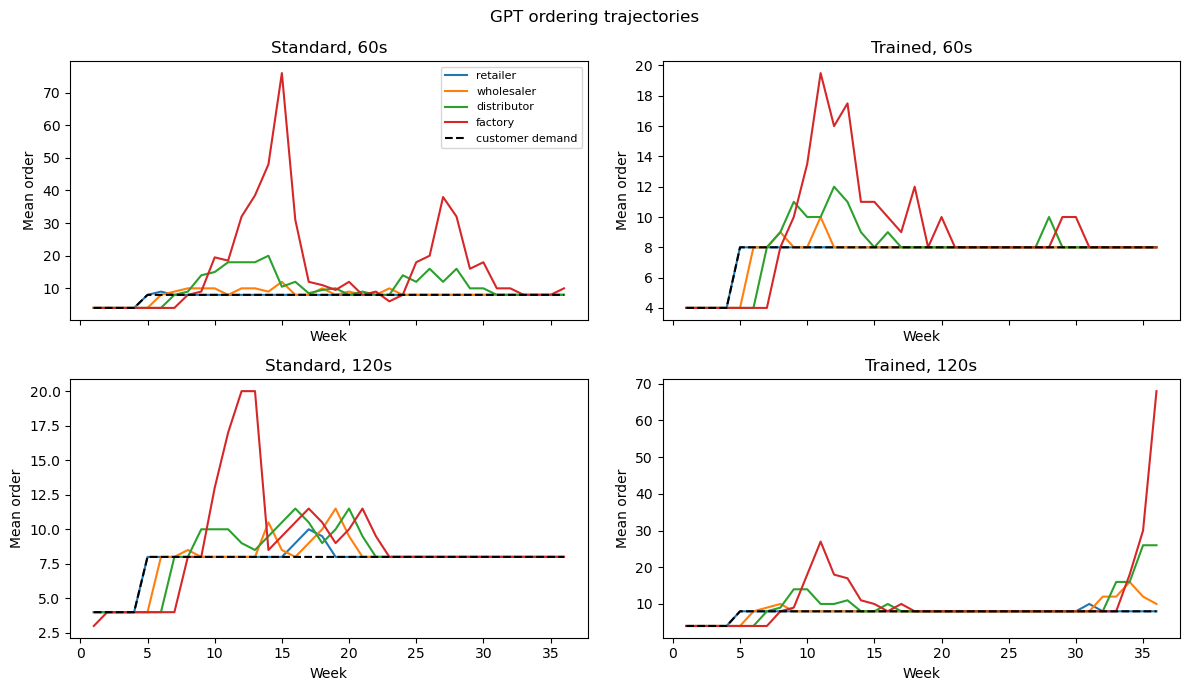

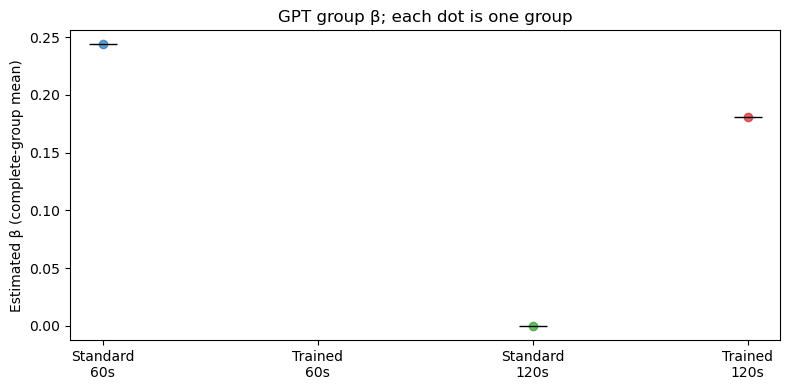

Outputs: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/results/api_023f89662165ca64


In [15]:
quality = rounds.assign(failed=~rounds.status.isin(["ok", "synthetic"]))
quality["near_deadline"] = quality.elapsed_s >= .9 * quality.deadline_s
checks = quality.groupby(["trained", "deadline_s"]).agg(
    decisions=("order", "size"), fallback_rate=("failed", "mean"),
    median_elapsed_s=("elapsed_s", "median"), max_elapsed_s=("elapsed_s", "max"),
    near_deadline_rate=("near_deadline", "mean"),
    input_tokens=("input_tokens", "sum"), output_tokens=("output_tokens", "sum"))
checks.to_csv(run_dir / "manipulation_checks.csv")
display(checks)
if "recovered_after_restart" in rounds.columns:
    recovery_summary = rounds.groupby(["trained", "deadline_s"]).agg(
        decisions_recovered_after_restart=("recovered_after_restart", "sum"),
        connection_failures_within_current_window=("connection_failures", "sum"))
    recovery_summary.to_csv(run_dir / "connection_recovery.csv")
    display(recovery_summary)
display(rounds.groupby(["trained", "deadline_s", "status"]).size().rename("count").reset_index())
performance = rounds.groupby(["group_id", "agent_id", "role", "trained", "deadline_s"]).agg(
    total_cost=("cost", "sum"), mean_backlog=("backlog", "mean"),
    order_variance=("order", "var"), incoming_variance=("demand", "var")).reset_index()
performance["bullwhip_ratio"] = performance.order_variance / performance.incoming_variance.replace(0, np.nan)
performance.to_csv(run_dir / "performance.csv", index=False)
display(performance)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, condition in zip(axes.flat, CONDITIONS):
    subset = rounds[(rounds.trained == condition.trained) & (rounds.deadline_s == condition.deadline_s)]
    for role in ROLES:
        mean = subset[subset.role == role].groupby("week").order.mean()
        ax.plot(mean.index, mean.values, label=role)
    ax.plot(range(1, WEEKS+1), DEMAND, "k--", label="customer demand")
    ax.set_title(f"{'Trained' if condition.trained else 'Standard'}, {condition.deadline_s}s")
    ax.set(xlabel="Week", ylabel="Mean order")
axes[0, 0].legend(fontsize=8)
fig.suptitle("SYNTHETIC PIPELINE CHECK" if MODE == "offline" else "GPT ordering trajectories")
fig.tight_layout()
fig.savefig(run_dir / "order_trajectories.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for pos, condition in enumerate(CONDITIONS):
    values = groups.loc[(groups.trained == condition.trained) &
                        (groups.deadline_s == condition.deadline_s) & groups.included, "beta"]
    ax.scatter(np.full(len(values), pos), values, alpha=.7)
    if len(values): ax.plot(pos, values.mean(), "k_", markersize=20)
ax.set_xticks(range(4))
ax.set_xticklabels([f"{'Trained' if c.trained else 'Standard'}\n{c.deadline_s}s" for c in CONDITIONS])
ax.set(ylabel="Estimated β (complete-group mean)",
       title="Synthetic check: group β" if MODE == "offline" else "GPT group β; each dot is one group")
fig.tight_layout()
fig.savefig(run_dir / "group_beta.png", dpi=160)
plt.show()
print("Outputs:", run_dir)


## 8. Before using this for the proposed student experiment

This notebook operationalizes the reflection's hypotheses for GPT sessions and rehearses data collection and analysis. It does not recruit students, deliver a human-facing timed interface, or supply evidence about undergraduates. Repeated GPT sessions may be highly similar and are not substitutes for 240 distinct people.

For a human study, retain the factorial contrasts and group-aware analysis, decide whether training is randomized by group or person, specify training/comprehension checks, enforce deadlines in the participant interface, record actual decision times, and preregister the simulator rules, fallback rule, fit bounds/exclusions, sample size justification, and primary contrast. The 240-person sample here comes from the reflection; it has not been justified by a power analysis. Validate β recovery under plausible human policies and alternative forecast/target assumptions before interpreting treatment differences.

Files: `manifest.json` records settings and versions; `requests/*.json` records the exact prompts, full returned responses, and status; `rounds.csv` records decisions and state; `agent_beta_fits.csv` records fit diagnostics; `group_beta.csv` records exclusions; `hypothesis_contrasts.csv` records estimates/intervals; `manipulation_checks.csv`, `performance.csv`, and PNG plots support interpretation. Preserve failed runs and report missingness. No API key is written by this notebook.
